In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/DataSet/ds07_thai_loan_default.csv")
df.head()

,applicant_id,age,occupation,region,monthly_income,years_employed,debt_to_income,num_credit_cards,late_payments_12m,home_status,has_guarantor,loan_amount,loan_term_months,collection_calls,default
0,A100000,52,freelance,North,31900.0,5.9,0.099,3,2,rent,no,306000,24,0,0
1,A100001,34,agriculture,South,9700.0,9.7,0.186,1,1,own,no,66000,60,0,0
2,A100002,46,self_employed,Northeast,27400.0,11.4,0.130,0,0,family,no,702000,60,8,1
3,A100003,27,private,Northeast,14500.0,3.5,0.498,2,0,own,no,280000,60,0,0
4,A100004,26,agriculture,Bangkok,10100.0,6.0,0.641,1,2,family,no,160000,60,4,1


In [ ]:
print(df.shape)
print(df.info())
print(df.describe())

(3000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   applicant_id       3000 non-null   object 
 1   age                3000 non-null   int64  
 2   occupation         3000 non-null   object 
 3   region             3000 non-null   object 
 4   monthly_income     2900 non-null   float64
 5   years_employed     2903 non-null   float64
 6   debt_to_income     3000 non-null   float64
 7   num_credit_cards   3000 non-null   int64  
 8   late_payments_12m  3000 non-null   int64  
 9   home_status        2932 non-null   object 
 10  has_guarantor      3000 non-null   object 
 11  loan_amount        3000 non-null   int64  
 12  loan_term_months   3000 non-null   int64  
 13  collection_calls   3000 non-null   int64  
 14  default            3000 non-null   int64  
dtypes: float64(3), int64(7), object(5)
memory usage: 351.7+ KB
No

# 1. Applicant Information (ข้อมูลผู้กู้)
* applicant_id = รหัสประจำตัวผู้สมัครสินเชื่อ
* age = อายุของผู้สมัคร
* occupation = อาชีพของผู้สมัคร
* region = ภูมิภาคที่อยู่อาศัย

# 2. Financial Information (ข้อมูลทางการเงิน)
* monthly_income = รายได้ต่อเดือน
* years_employed = จำนวนปีที่ทำงาน
* debt_to_income = สัดส่วนหนี้สินต่อรายได้
* num_credit_cards = จำนวนบัตรเครดิต
* late_payments_12m = จำนวนครั้งที่ชำระเงินล่าช้าในช่วง 12 เดือนที่ผ่านมา

# 3. Loan Information (ข้อมูลสินเชื่อ)
* home_status = สถานะที่อยู่อาศัย
* has_guarantor = มีผู้ค้ำประกันหรือไม่
* loan_amount = จำนวนเงินกู้
* loan_term_months = ระยะเวลาการกู้ (เดือน)
* collection_calls = จำนวนครั้งที่มีการติดตามทวงถามหนี้
* default = สถานะการผิดนัดชำระหนี้
* 0 = ไม่ผิดนัดชำระหนี้
* 1 = ผิดนัดชำระหนี้


In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
monthly_income,100
years_employed,97
home_status,68
occupation,0
age,0
region,0
applicant_id,0
debt_to_income,0
num_credit_cards,0
late_payments_12m,0


Accurancy:  0.9916666666666667
Confusion Matrix: 
 [[515   4]
 [  1  80]]
Classification Report: 
               precision    recall  f1-score   support

           0       1.00      0.99      1.00       519
           1       0.95      0.99      0.97        81

    accuracy                           0.99       600
   macro avg       0.98      0.99      0.98       600
weighted avg       0.99      0.99      0.99       600

Result:  [0]


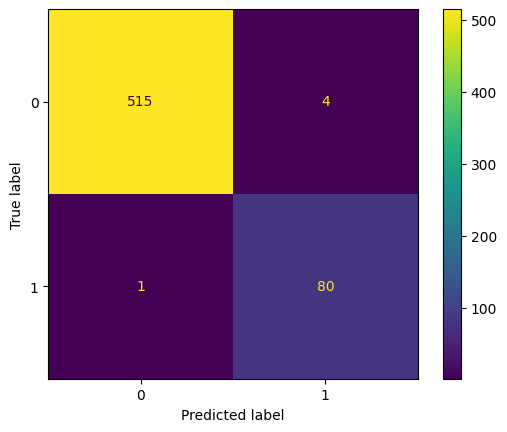

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

#Features
x = df.drop(columns=['applicant_id', 'default'])

#Label
y = df['default']

#แบ่งประเภทข้อมูล
numeric_features = x.select_dtypes(include=['int64', 'float64']).columns
categorical_features = x.select_dtypes(include=['object']).columns

#Splilit Data
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

# จัดการ Missing Values ของข้อมูลตัวเลข
from sklearn.impute import SimpleImputer

imputer_num = SimpleImputer(strategy='median')
x_train_num = imputer_num.fit_transform(x_train[numeric_features])
x_test_num = imputer_num.transform(x_test[numeric_features])

# จัดการ Missing Values ของข้อมูลข้อความ
imputer_cat = SimpleImputer(strategy='most_frequent')
x_train_cat = imputer_cat.fit_transform(x_train[categorical_features])
x_test_cat = imputer_cat.transform(x_test[categorical_features])

#ทำOnehot Encoder
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

x_train_encoded = encoder.fit_transform(x_train_cat)
x_test_encoded = encoder.transform(x_test_cat)

#ทำStandardization
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train_num)
x_test_scaled = scaler.transform(x_test_num)

# รวมข้อมูลตัวเลขและข้อความ
x_train = np.concatenate([x_train_scaled, x_train_encoded], axis=1)
x_test = np.concatenate([x_test_scaled, x_test_encoded], axis=1)

Gaussian_model = GaussianNB()
Gaussian_model.fit(x_train,y_train)
y_pred = Gaussian_model.predict(x_test)
accuracy1 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy1)
confusion_matrix1 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix1)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display1 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=Gaussian_model.classes_)
matrix_display1.plot()

# Predict X (Loan Default)
result = Gaussian_model.predict(x_test[:1])
print("Result: ", result)


Accurancy:  0.9883333333333333
Confusion Matrix: 
 [[519   0]
 [  7  74]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       519
           1       1.00      0.91      0.95        81

    accuracy                           0.99       600
   macro avg       0.99      0.96      0.97       600
weighted avg       0.99      0.99      0.99       600

Result:  [0]


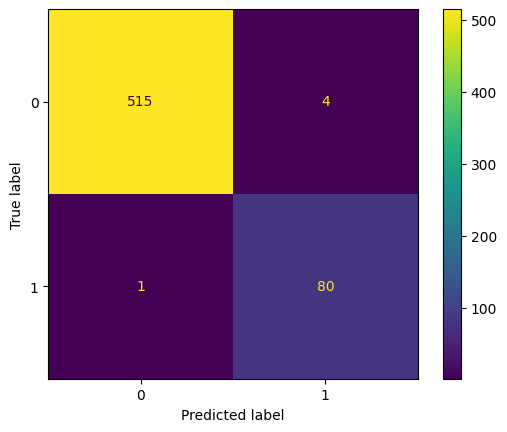

In [ ]:
#Classification with Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

Logistic_model = LogisticRegression()
Logistic_model.fit(x_train,y_train)
y_pred = Logistic_model.predict(x_test)
accuracy2 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy2)
confusion_matrix2 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix2)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display2 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=Logistic_model.classes_)
matrix_display2.plot()

# Predict X (Loan Default)
result = Logistic_model.predict(x_test[:1])
print("Result: ", result)

Accurancy:  0.9883333333333333
Confusion Matrix: 
 [[519   0]
 [  7  74]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       519
           1       1.00      0.91      0.95        81

    accuracy                           0.99       600
   macro avg       0.99      0.96      0.97       600
weighted avg       0.99      0.99      0.99       600

Result:  [0]


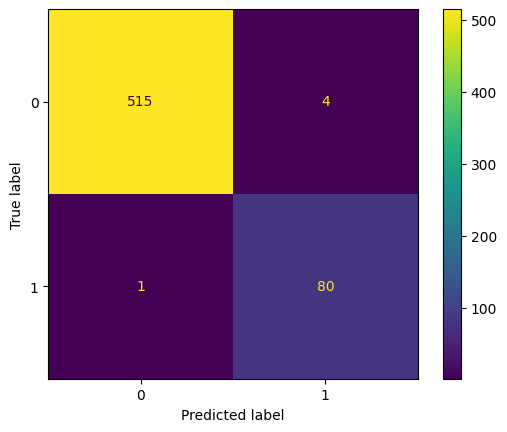

In [ ]:
 #Classification with SVM
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

SVM_model = SVC()
SVM_model.fit(x_train,y_train)
y_pred = SVM_model.predict(x_test)
accuracy3 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy3)
confusion_matrix3 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix3)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display3 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=SVM_model.classes_)
matrix_display3.plot()

# Predict X (Loan Default)
result = SVM_model.predict(x_test[:1])
print("Result: ", result)

Accurancy:  0.9883333333333333
Confusion Matrix: 
 [[519   0]
 [  7  74]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       519
           1       1.00      0.91      0.95        81

    accuracy                           0.99       600
   macro avg       0.99      0.96      0.97       600
weighted avg       0.99      0.99      0.99       600

Result:  [0]


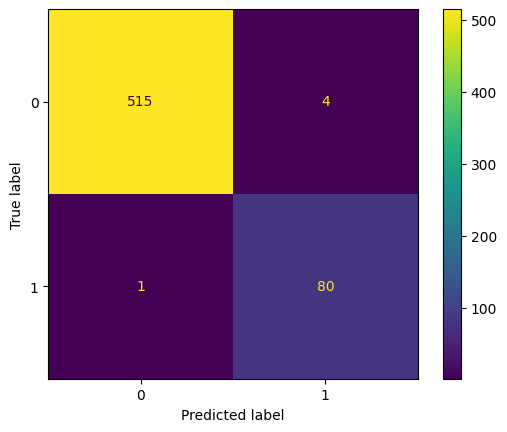

In [ ]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

forest_model = RandomForestClassifier()
forest_model.fit(x_train,y_train)
y_pred = forest_model.predict(x_test)
accuracy4 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy4)
confusion_matrix4 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix4)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display4 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=forest_model.classes_)
matrix_display4.plot()

# Predict X (Loan Default)
result = forest_model.predict(x_test[:1])
print("Result: ", result)

Accurancy:  0.9683333333333334
Confusion Matrix: 
 [[519   0]
 [ 19  62]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.96      1.00      0.98       519
           1       1.00      0.77      0.87        81

    accuracy                           0.97       600
   macro avg       0.98      0.88      0.92       600
weighted avg       0.97      0.97      0.97       600

Result:  [0]


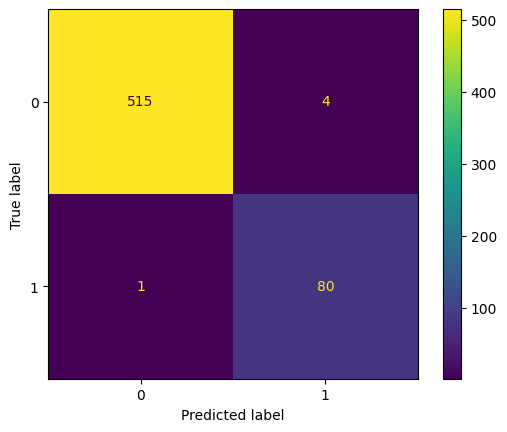

In [ ]:
#KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

KNN_model = KNeighborsClassifier()
KNN_model.fit(x_train,y_train)
y_pred = KNN_model.predict(x_test)
accuracy5 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy5)
confusion_matrix5 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix5)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display5 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=KNN_model.classes_)
matrix_display5.plot()

# Predict X (Loan Default)
result = KNN_model.predict(x_test[:1])
print("Result: ", result)

Accurancy:  0.985
Confusion Matrix: 
 [[517   2]
 [  7  74]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       519
           1       0.97      0.91      0.94        81

    accuracy                           0.98       600
   macro avg       0.98      0.95      0.97       600
weighted avg       0.98      0.98      0.98       600

Result:  [0]


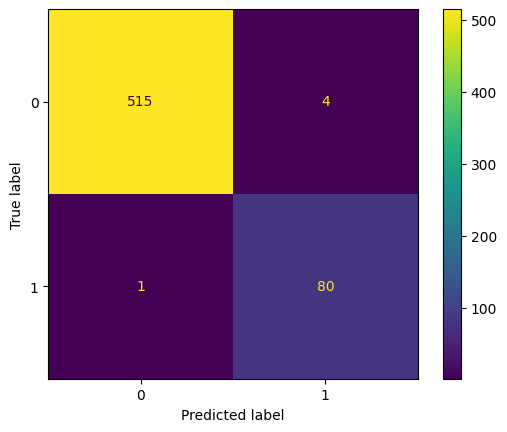

In [ ]:
#Nerual Network
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

Nerual_model = MLPClassifier(
    hidden_layer_sizes=(20,10),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)
Nerual_model.fit(x_train,y_train)
y_pred = Nerual_model.predict(x_test)
accuracy6 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy6)
confusion_matrix6 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix6)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display6 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=Nerual_model.classes_)
matrix_display6.plot()

# Predict X (Loan Default)
result = Nerual_model.predict(x_test[:1])
print("Result: ", result)

In [ ]:
#เปรียบเทียบโมเดลเพื่อหาว่าโมเดลใดเหมาะกับข้อมูล Loan
print("Accurancy of Neive Bayes: ",accuracy1)
print("Accurancy of Logistic Regression: ",accuracy2)
print("Accurancy of SVM: ",accuracy3)
print("Accurancy of Random Forest: ",accuracy4)
print("Accurancy of KNN: ",accuracy5)
print("Accurancy of Nerual Network: ",accuracy6)
print("----------------------------------------------------------")

def f1_score(tp,fp,fn):
  precision_score = tp/(tp+fp)
  recall_score = tp/(tp+fn)
  f1_score = 2*(precision_score*recall_score)/(precision_score+recall_score)
  return f1_score

#f1-naive bayes
tn,fp,fn,tp = confusion_matrix1[0,0],confusion_matrix1[0,1],confusion_matrix1[1,0],confusion_matrix1[1,1]
f1_nb = f1_score(tp,fp,fn)
print("f1-score of Neive Bayes: ",f1_nb)

#f1-logistic regression
tn,fp,fn,tp = confusion_matrix2[0,0],confusion_matrix2[0,1],confusion_matrix2[1,0],confusion_matrix2[1,1]
f1_lr = f1_score(tp,fp,fn)
print("f1-score of Logistic Regression: ",f1_lr)

#f1-svm
tn,fp,fn,tp = confusion_matrix3[0,0],confusion_matrix3[0,1],confusion_matrix3[1,0],confusion_matrix3[1,1]
f1_svm = f1_score(tp,fp,fn)
print("f1-score of SVM: ",f1_svm)

#f1-random forest
tn,fp,fn,tp = confusion_matrix4[0,0],confusion_matrix4[0,1],confusion_matrix4[1,0],confusion_matrix4[1,1]
f1_rf = f1_score(tp,fp,fn)
print("f1-score of Random Forest: ",f1_rf)

#f1-KNN
tn,fp,fn,tp = confusion_matrix5[0,0],confusion_matrix5[0,1],confusion_matrix5[1,0],confusion_matrix5[1,1]
f1_knn = f1_score(tp,fp,fn)
print("f1-score of KNN: ",f1_knn)

#f1-nerual network
tn,fp,fn,tp = confusion_matrix6[0,0],confusion_matrix6[0,1],confusion_matrix6[1,0],confusion_matrix6[1,1]
f1_nn = f1_score(tp,fp,fn)
print("f1-score of Nerual Network: ",f1_nn)

Accurancy of Neive Bayes:  0.9916666666666667
Accurancy of Logistic Regression:  0.9883333333333333
Accurancy of SVM:  0.9883333333333333
Accurancy of Random Forest:  0.9883333333333333
Accurancy of KNN:  0.9683333333333334
Accurancy of Nerual Network:  0.985
----------------------------------------------------------
f1-score of Neive Bayes:  0.9696969696969696
f1-score of Logistic Regression:  0.9548387096774192
f1-score of SVM:  0.9548387096774192
f1-score of Random Forest:  0.9548387096774192
f1-score of KNN:  0.8671328671328672
f1-score of Nerual Network:  0.9426751592356688
